# Cross-Border Flows Monitor: Asia & EM

Foreign investors are the marginal price-setter in many Asian and emerging markets. VandaXasset collects their flows
from exchanges, custodians and central banks into one consistent format. This notebook builds a monitor across
**17 foreign-flow series** in equities and bonds:

1. Assemble the panel and check each series' cadence
2. Harmonise to monthly USD
3. Build the monitor: this month's flows against each market's own history
4. Score recent flows across markets
5. Track EM Asia equity flows and their breadth, week by week
6. Follow China's Stock Connect, Southbound

In [1]:
import sys
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
qk.set_style()

## 1. The panel

Each entry is *(series, dataset, metric, market, asset)*. Korea reports `net_value` (USD) separately from
`net_volume` (shares); every other source reports `net`.

In [2]:
PANEL = [
    ("CNEQASHRFORINSMIXMIX", "cn_stock_connect_flows", "net", "China A (Northbound)", "Equity"),
    ("CNEQHSHRDOMMIXMIXMIX", "cn_stock_connect_flows", "net", "Hong Kong (Southbound)", "Equity"),
    ("INEQSTCKFORINSMIXMIX", "in_foreign_flows_by_instrument", "net", "India", "Equity"),
    ("JPEQSTCKFORINSMIXMIX", "jp_investor_flows", "net", "Japan", "Equity"),
    ("KREQSTCKFORMIXMIXMIX", "kr_investor_flows", "net_value", "Korea", "Equity"),
    ("TWEQSTCKFORINSMIXMIX", "tw_equity_flows", "net", "Taiwan", "Equity"),
    ("PHEQSTCKFORINSMIXMIX", "ph_equity_foreign_flows", "net", "Philippines", "Equity"),
    ("TREQSTCKFORINSMIXMIX", "tr_foreign_flows", "net", "Turkey", "Equity"),
    ("BRFIBONDFORINSMIXMIX", "br_fixed_income_foreign_flows", "net", "Brazil", "Bonds"),
    ("CNFIBONDFORINSMIXMIX", "cn_fixed_income_flows", "net", "China", "Bonds"),
    ("IDFIBONDFORINSMIXMIX", "id_fixed_income_flows", "net", "Indonesia", "Bonds"),
    ("INFIBONDFORINSMIXMIX", "in_foreign_flows_by_instrument", "net", "India", "Bonds"),
    ("JPFIBONDLTFORINSMIXMIX", "jp_investor_flows", "net", "Japan (long-term)", "Bonds"),
    ("MXFIBONDFORINSMIXMIX", "mx_fixed_income_foreign_flows", "net", "Mexico", "Bonds"),
    ("MYFIBONDFORMIXMIXMIX", "my_fixed_income_foreign_flows", "net", "Malaysia", "Bonds"),
    ("PHFIBONDFORMIXMIXMIX", "ph_fixed_income_foreign_flows", "net", "Philippines", "Bonds"),
    ("TRFIBONDFORINSMIXMIX", "tr_foreign_flows", "net", "Turkey", "Bonds"),
]

raw, audit = {}, []
for label, dataset, metric, market, asset in PANEL:
    df = qk.load("flow", dataset, series=label, metrics=metric)
    s = df.set_index("ts")["value"]
    raw[label] = s
    audit.append({
        "market": market, "asset": asset, "label": label, "unit": df.unit.iloc[0],
        "median gap (days)": s.index.to_series().diff().dt.days.median(),
        "from": s.index.min().date(), "to": s.index.max().date(),
    })
audit = pd.DataFrame(audit)
audit

,market,asset,label,unit,median gap (days),from,to
0,China A (Northbound),Equity,CNEQASHRFORINSMIXMIX,USDmn,1.0,2019-11-12,2024-08-20
1,Hong Kong (Southbound),Equity,CNEQHSHRDOMMIXMIXMIX,USDmn,1.0,2014-11-17,2026-04-10
2,India,Equity,INEQSTCKFORINSMIXMIX,USDmn,1.0,2009-11-30,2026-04-10
3,Japan,Equity,JPEQSTCKFORINSMIXMIX,USDmn,7.0,2005-01-07,2026-04-10
4,Korea,Equity,KREQSTCKFORMIXMIXMIX,USDmn,1.0,2015-05-04,2026-04-10
5,Taiwan,Equity,TWEQSTCKFORINSMIXMIX,USDmn,1.0,2012-05-02,2026-04-10
6,Philippines,Equity,PHEQSTCKFORINSMIXMIX,USDmn,1.0,2021-01-15,2026-04-10
7,Turkey,Equity,TREQSTCKFORINSMIXMIX,USDmn,7.0,2020-09-11,2026-04-10
8,Brazil,Bonds,BRFIBONDFORINSMIXMIX,USDmn,31.0,2007-02-28,2026-03-31
9,China,Bonds,CNFIBONDFORINSMIXMIX,USDmn,31.0,2017-10-31,2026-03-31


**Cadences differ.** Sources publish daily, weekly or monthly; the `median gap` column shows each series' effective
cadence. Rolling windows measured in observations would mean different horizons for each, so the next step puts
everything on one calendar grid. China Northbound ends in August 2024 in this export, when daily Northbound
disclosure stopped.

## 2. Harmonise to monthly USD

Every series in the panel is in USD mn, and flows are summable over time (`measure_class = flow`), so monthly totals are
a plain resample.

In [3]:
assert (audit.unit == "USDmn").all(), audit[audit.unit != "USDmn"]
monthly = pd.DataFrame({(asset, market): raw[label].resample("ME").sum(min_count=1) for label, dataset, metric, market, asset in PANEL}).loc["2010":]
monthly.columns = pd.MultiIndex.from_tuples(monthly.columns, names=["asset", "market"])
(monthly.tail(6) / 1_000).round(1)

asset                    Equity                                                                     Bonds                                                                           
market     China A (Northbound) Hong Kong (Southbound) India Japan Korea Taiwan Philippines Turkey Brazil China Indonesia India Japan (long-term) Mexico Malaysia Philippines Turkey
ts                                                                                                                                                                                  
2025-11-30                  NaN                   11.5  -1.3  -2.2  -9.7   -9.6        -0.2   -0.1   -4.8  -1.0      -0.4   0.4              11.9    0.8      2.5         0.4    1.6
2025-12-31                  NaN                    1.6  -3.5  -1.8   2.4   -2.5        -0.2    0.8    7.0  -3.5       0.4  -1.7               2.4    1.6      2.0         0.5    0.3
2026-01-31                  NaN                    4.1  -3.6  15.0   0.4   -0.4         0.1    1.5    2.0  -4.3       0.0   1.1              33.3    3.3      2.4         3.8    4.2
2026-02-28                  NaN                    6.0   1.2  18.4 -13.7    3.6         0.1    0.9    3.1   5.6      -0.2   1.3              15.4    0.5      0.4        -0.1    0.4
2026-03-31                  NaN                    0.7 -12.4 -14.3 -23.8  -25.2        -0.2   -1.1   -3.1 -10.1      -1.3  -1.5             -11.9    1.3     -1.5        -0.5   -6.1
2026-04-30                  NaN                   -0.5  -5.1  22.3   3.7    4.3        -0.1    0.2    NaN   NaN       0.3  -1.3              19.6   -0.1      2.1         NaN   -0.1

## 3. The monitor: this month versus each market's own history

Dollar flows are not comparable across markets: $1bn matters far more in Manila than in Tokyo. Each market's monthly
flow is scored against its **own trailing 5-year history** (minimum 24 months), so a +2 means an unusually large inflow
*for that market*.

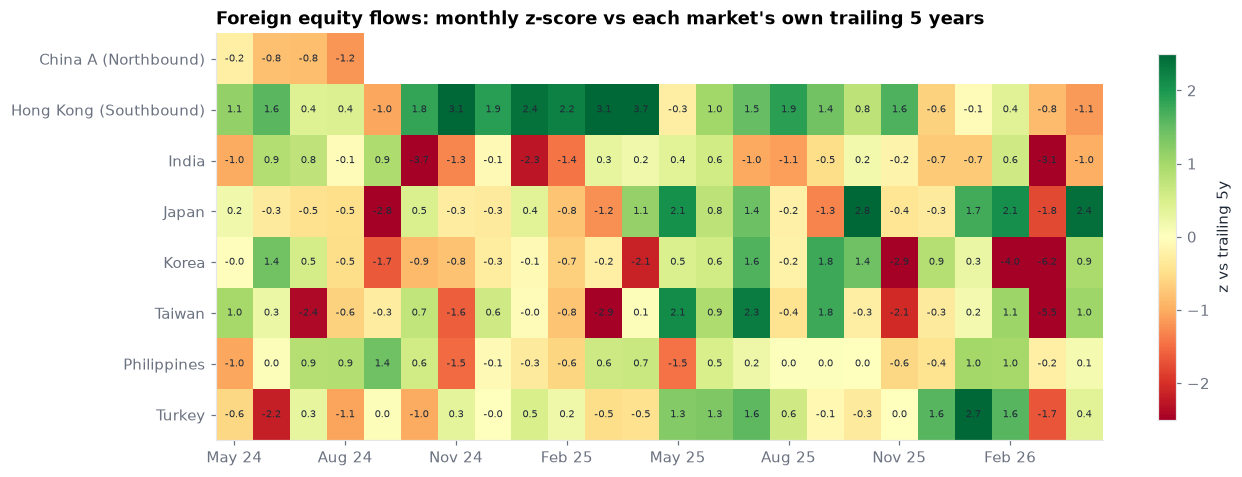

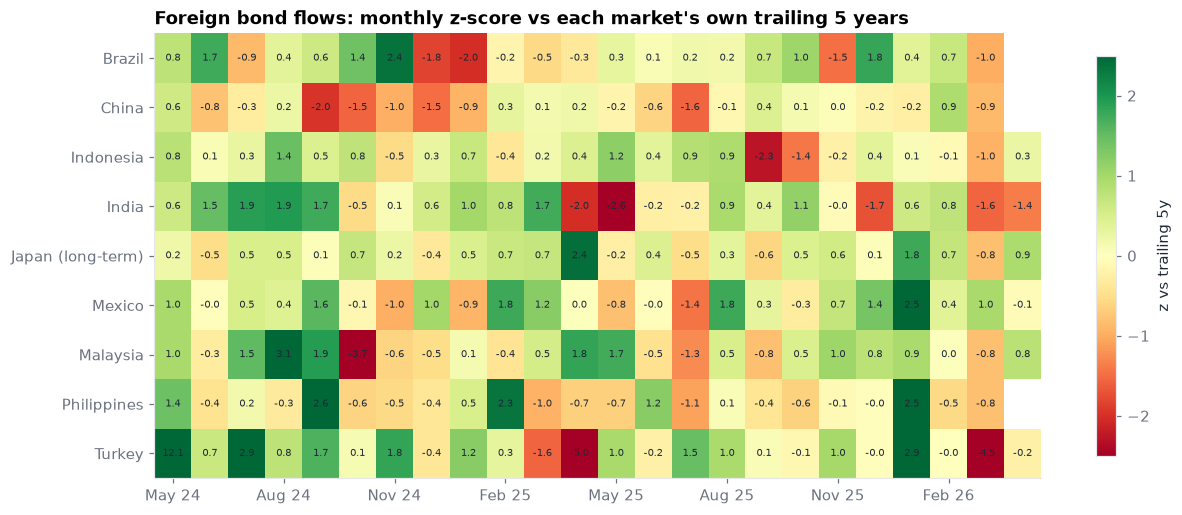

In [4]:
def trailing_z(s: pd.Series, window: int = 60, min_periods: int = 24) -> pd.Series:
    past = s.shift(1).rolling(window, min_periods=min_periods)
    return (s - past.mean()) / past.std()


scores = monthly.apply(trailing_z)
recent = scores.iloc[-24:]


def heatmap(block: pd.DataFrame, title: str) -> None:
    fig, ax = plt.subplots(figsize=(13, 0.45 * block.shape[1] + 1.2))
    im = ax.imshow(block.T.values, aspect="auto", cmap="RdYlGn", vmin=-2.5, vmax=2.5)
    ax.set_yticks(range(block.shape[1]), block.columns)
    ax.set_xticks(range(0, len(block), 3), [d.strftime("%b %y") for d in block.index[::3]])
    for (i, j), v in np.ndenumerate(block.T.values):
        if np.isfinite(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5, color=qk.VANDA["ink"])
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.9, label="z vs trailing 5y")
    ax.set_title(title)
    plt.show()


heatmap(recent["Equity"], "Foreign equity flows: monthly z-score vs each market's own trailing 5 years")
heatmap(recent["Bonds"], "Foreign bond flows: monthly z-score vs each market's own trailing 5 years")

## 4. Scoreboard

The latest 1-, 3- and 12-month totals in USD bn, plus the 3-month total's z-score against the market's history of
3-month totals.

In [5]:
def scoreboard(m: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for col in m.columns:
        s = m[col].dropna()
        if s.empty:
            continue
        roll3 = s.rolling(3).sum()
        rows[col] = {
            "last month": s.index[-1].strftime("%b %Y"),
            "1m $bn": s.iloc[-1] / 1_000,
            "3m $bn": roll3.iloc[-1] / 1_000,
            "12m $bn": s.iloc[-12:].sum() / 1_000,
            "3m z": (roll3.iloc[-1] - roll3.iloc[:-1].mean()) / roll3.iloc[:-1].std(),
        }
    return pd.DataFrame(rows).T


board = scoreboard(monthly)
board[["1m $bn", "3m $bn", "12m $bn", "3m z"]] = board[["1m $bn", "3m $bn", "12m $bn", "3m z"]].astype(float).round(2)
board.sort_values("3m z")

last month  1m $bn  3m $bn  12m $bn  3m z
Equity Korea                    Apr 2026    3.66  -33.87   -25.76 -4.95
       India                    Apr 2026   -5.06  -16.27   -33.17 -2.65
       Taiwan                   Apr 2026    4.33  -17.24   -10.38 -2.45
Bonds  Turkey                   Apr 2026   -0.07   -5.81     6.03 -2.33
Equity China A (Northbound)     Aug 2024   -2.74   -5.05    -6.02 -1.39
Bonds  Indonesia                Apr 2026    0.26   -1.23    -1.74 -0.95
       India                    Apr 2026   -1.27   -1.40    -0.11 -0.60
       China                    Mar 2026  -10.13   -8.80   -33.47 -0.52
Equity Hong Kong (Southbound)   Apr 2026   -0.51    6.14    73.82 -0.44
Bonds  Mexico                   Apr 2026   -0.10    1.64     5.55 -0.07
       Malaysia                 Apr 2026    2.09    1.05    10.61  0.03
Equity Turkey                   Apr 2026    0.21    0.07     4.35  0.11
Bonds  Brazil                   Mar 2026   -3.15    1.95    15.31  0.21
Equity Philippines              Apr 2026   -0.09   -0.20    -1.43  0.45
Bonds  Japan (long-term)        Apr 2026   19.61   23.07    77.48  0.64
Equity Japan                    Apr 2026   22.30   26.41    83.91  1.41
Bonds  Philippines              Mar 2026   -0.50    3.16     5.37  1.52

## 5. EM Asia equities, week by week

For tactical work, the daily sources (Korea, Taiwan, India and the Philippines) can be summed weekly into one EM Asia
foreign equity flow. Two complementary reads:

* **Size:** the rolling 13-week sum in USD bn
* **Breadth:** how many of the four markets had net foreign buying over the past four weeks. A broad bid is more durable
  than one market doing all the work.

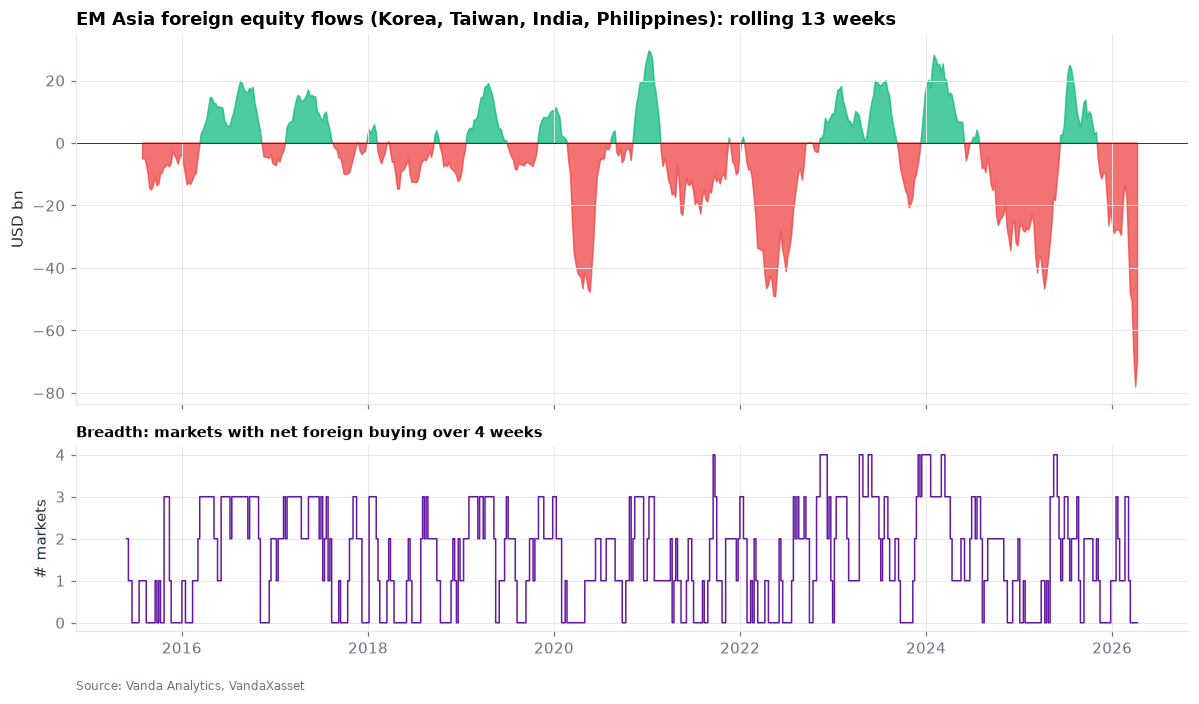

In [6]:
asia_labels = {"KREQSTCKFORMIXMIXMIX": "Korea", "TWEQSTCKFORINSMIXMIX": "Taiwan", "INEQSTCKFORINSMIXMIX": "India", "PHEQSTCKFORINSMIXMIX": "Philippines"}
weekly = pd.DataFrame({name: raw[label].resample("W-FRI").sum(min_count=1) for label, name in asia_labels.items()}).loc["2015":]
weekly = weekly.fillna(0).where(weekly.ffill().notna())  # a holiday week is zero flow, not missing

total_13w = weekly.sum(axis=1, min_count=3).rolling(13).sum() / 1_000
four_week = weekly.rolling(4).sum()
breadth = (four_week > 0).sum(axis=1).where(four_week.notna().sum(axis=1) >= 3)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax1.fill_between(total_13w.index, total_13w, where=total_13w >= 0, color=qk.VANDA["pos"], alpha=0.75, interpolate=True)
ax1.fill_between(total_13w.index, total_13w, where=total_13w < 0, color=qk.VANDA["neg"], alpha=0.75, interpolate=True)
ax1.axhline(0, color=qk.VANDA["ink"], lw=0.6)
ax1.set_ylabel("USD bn")
ax1.set_title("EM Asia foreign equity flows (Korea, Taiwan, India, Philippines): rolling 13 weeks")
ax2.step(breadth.index, breadth, color=qk.VANDA["purple"], where="post", lw=1)
ax2.set_ylabel("# markets")
ax2.set_yticks(range(0, 5))
ax2.set_title("Breadth: markets with net foreign buying over 4 weeks", fontsize=10)
qk.source_note(ax2)
plt.tight_layout()
plt.show()

## 6. China Stock Connect: Southbound

Mainland investors buying Hong Kong-listed shares through Stock Connect have been a persistent structural bid. The
dataset also breaks Southbound down by sector:

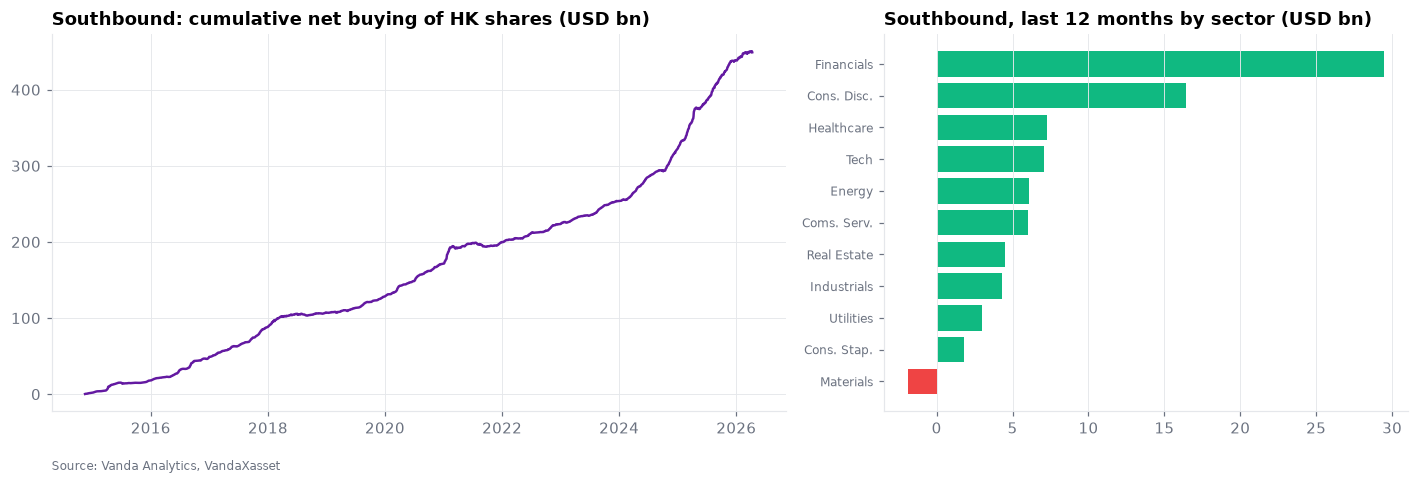

In [7]:
south_sectors = qk.load("flow", "cn_stock_connect_flows", metrics="net")
south_sectors = south_sectors[south_sectors.series_label.str.startswith("CNEQHSHRDOMMIXMIXMIX-")]
names = qk.names(south_sectors.series_label.unique())
by_sector = qk.pivot(south_sectors).rename(columns=lambda c: names[c].replace("China Mainland H-Shares ", ""))

last_12m = (by_sector.loc[by_sector.index.max() - pd.DateOffset(months=12):].sum() / 1_000).sort_values()
cumulative = raw["CNEQHSHRDOMMIXMIXMIX"].cumsum() / 1_000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
ax1.plot(cumulative.index, cumulative, color=qk.VANDA["purple"], lw=1.6)
ax1.set_title("Southbound: cumulative net buying of HK shares (USD bn)")
ax2.barh(last_12m.index, last_12m, color=[qk.VANDA["pos"] if v > 0 else qk.VANDA["neg"] for v in last_12m])
ax2.set_title("Southbound, last 12 months by sector (USD bn)")
ax2.tick_params(axis="y", labelsize=8)
ax2.grid(axis="y", visible=False)
qk.source_note(ax1)
plt.tight_layout()
plt.show()

---
**Next:** `08 - Who Is On The Other Side`: CFTC trader categories, futures aggressors and dealer gamma.